# ___Haberman_Data_Analysis___

## _Dataset Detail_

**Title :-** `Haberman's Survival Data`

**Sources :-**

* **Donor :-** Tjen-Sien Lim (<limt@stat.wisc.edu>)

* **Date :-** $March$ $4, 1999$

**Past Usage :-**

* Haberman, S. J. ($1976$). Generalized Residuals for Log-Linear
Models, Proceedings of the $9th$ International Biometrics
Conference, Boston, pp. $104-122$.
 
* Landwehr, J. M., Pregibon, D., and Shoemaker, A. C. ($1984$),
Graphical Models for Assessing Logistic Regression Models (with
discussion), Journal of the American Statistical Association $79:
61-83$.

* Lo, W.-D. ($1993$). Logistic Regression Trees, PhD thesis,
Department of Statistics, University of Wisconsin, Madison, WI.

**Relevant Information :-** The dataset contains cases from a study that was conducted between
$1958$ and $1970$ at the `University of Chicago's` Billings Hospital on
the survival of patients who had undergone surgery for breast
cancer.

**Number of Instances :-** $306$

**Number of Attributes :-** $4$ (including the class attribute)

**Attribute Information :-**

* Age of patient at time of operation ($numerical$)
* Patient's year of operation (year - $1900$, $numerical$)
* Number of positive axillary nodes detected ($numerical$)
* Survival status (class attribute)
	* $1$ = the patient survived $5$ years or longer
	* $2$ = the patient died within $5$ year

**Missing Attribute Values :-** $None$





## *Dataset Configuration*

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sbn
import plotly.express as px

In [41]:
haberman = pd.read_csv("Haberman.csv", header=None)

In [42]:
haberman.columns = ["age", "operation_year", "axil_nodes", "survival_status"]

In [43]:
haberman

,age,operation_year,axil_nodes,survival_status
0,30,64,1,1
1,30,62,3,1
2,30,65,0,1
3,31,59,2,1
4,31,65,4,1
...,...,...,...,...
301,75,62,1,1
302,76,67,0,1
303,77,65,3,1
304,78,65,1,2


## _High level statistics of the dataset_

In [44]:
haberman.describe()

,age,operation_year,axil_nodes,survival_status
count,306.000000,306.000000,306.000000,306.000000
mean,52.457516,62.852941,4.026144,1.264706
std,10.803452,3.249405,7.189654,0.441899
min,30.000000,58.000000,0.000000,1.000000
25%,44.000000,60.000000,0.000000,1.000000
50%,52.000000,63.000000,1.000000,1.000000
75%,60.750000,65.750000,4.000000,2.000000
max,83.000000,69.000000,52.000000,2.000000


In [45]:
haberman.head()

,age,operation_year,axil_nodes,survival_status
0,30,64,1,1
1,30,62,3,1
2,30,65,0,1
3,31,59,2,1
4,31,65,4,1


In [46]:
df = haberman.sample(frac=0.10).head()
df

,age,operation_year,axil_nodes,survival_status
28,38,62,3,1
109,48,67,7,2
107,48,58,11,2
106,47,66,12,1
187,55,69,3,1


In [47]:
hm = haberman.sample(n=10).head()
hm

,age,operation_year,axil_nodes,survival_status
70,43,63,2,1
303,77,65,3,1
293,72,63,0,2
72,43,66,4,1
193,56,66,2,1


## _Numbers of points_

In [48]:
haberman.shape

(306, 4)

In [49]:
haberman.value_counts()

age  operation_year  axil_nodes  survival_status
61   59              0           1                  3
37   63              0           1                  2
38   60              0           1                  2
41   65              0           1                  2
43   64              0           2                  2
                                                   ..
75   62              1           1                  1
76   67              0           1                  1
77   65              3           1                  1
78   65              1           2                  1
83   58              2           2                  1
Name: count, Length: 289, dtype: int64

In [50]:
haberman["age"].value_counts()

age
52    14
54    13
50    12
43    11
47    11
53    11
57    11
38    10
41    10
49    10
55    10
65    10
42     9
45     9
61     9
59     8
63     8
34     7
44     7
46     7
48     7
56     7
58     7
62     7
70     7
37     6
39     6
51     6
60     6
67     6
64     5
66     5
69     4
72     4
30     3
40     3
31     2
33     2
35     2
36     2
68     2
73     2
74     2
71     1
75     1
76     1
77     1
78     1
83     1
Name: count, dtype: int64

In [51]:
haberman["operation_year"].value_counts()

operation_year
58    36
64    31
63    30
65    28
60    28
66    28
59    27
61    26
67    25
62    23
68    13
69    11
Name: count, dtype: int64

In [52]:
haberman["axil_nodes"].value_counts()

axil_nodes
0     136
1      41
3      20
2      20
4      13
7       7
6       7
8       7
9       6
5       6
13      5
11      4
14      4
10      3
15      3
23      3
19      3
22      3
20      2
12      2
30      1
21      1
52      1
16      1
24      1
46      1
18      1
35      1
17      1
25      1
28      1
Name: count, dtype: int64

In [53]:
haberman["survival_status"].value_counts()

survival_status
1    225
2     81
Name: count, dtype: int64

In [54]:
haberman.info()

<class 'pandas.DataFrame'>
RangeIndex: 306 entries, 0 to 305
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              306 non-null    int64
 1   operation_year   306 non-null    int64
 2   axil_nodes       306 non-null    int64
 3   survival_status  306 non-null    int64
dtypes: int64(4)
memory usage: 9.7 KB


In [55]:
haberman["survival_status"] = haberman["survival_status"].map({1: "yes", 2: "no"})
print(haberman.head(15))

    age  operation_year  axil_nodes survival_status
0    30              64           1             yes
1    30              62           3             yes
2    30              65           0             yes
3    31              59           2             yes
4    31              65           4             yes
5    33              58          10             yes
6    33              60           0             yes
7    34              59           0              no
8    34              66           9              no
9    34              58          30             yes
10   34              60           1             yes
11   34              61          10             yes
12   34              67           7             yes
13   34              60           0             yes
14   35              64          13             yes


In [56]:
haberman["survival_status"].value_counts()

survival_status
yes    225
no      81
Name: count, dtype: int64

In [57]:
haberman.info()

<class 'pandas.DataFrame'>
RangeIndex: 306 entries, 0 to 305
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              306 non-null    int64
 1   operation_year   306 non-null    int64
 2   axil_nodes       306 non-null    int64
 3   survival_status  306 non-null    str  
dtypes: int64(3), str(1)
memory usage: 9.7 KB


## _Numbers of features_

In [58]:
haberman.columns

Index(['age', 'operation_year', 'axil_nodes', 'survival_status'], dtype='str')

In [59]:
haberman.columns[:-1]

Index(['age', 'operation_year', 'axil_nodes'], dtype='str')

In [60]:
haberman.columns[0]

'age'

In [61]:
haberman.columns[-1]

'survival_status'

## _Numbers of classes_

In [62]:
print(haberman["survival_status"].unique())

<StringArray>
['yes', 'no']
Length: 2, dtype: str


In [63]:
haberman["survival_status"].unique()

<StringArray>
['yes', 'no']
Length: 2, dtype: str

## _Data points per class_

In [64]:
haberman.groupby("survival_status").count()

,age,operation_year,axil_nodes
survival_status,,,
no,81,81,81
yes,225,225,225


## _Univaraite analysis_

Univaraite analysis is the simplest from of anlyzing data. "Uni" means "one", so in other words your data has only one variable. It does not deal with causes or relationships (unlike re gression) and it's major purpose is to describe; It takes data, summarizes that data and finds patterns in the data. It provides summary statistics for each field in the raw data ser. Example : PDF, CDF, Boxplot, Violinplot. It does not deal with cause or relationships and the main purpose of the analysis is to describe the data and find patterns that exist within it.

### _PDF (Probability Density Function)_

Probability density function (PDF) is a statistical expression that defines a probability distribution (the likelihood of an outcome) for a continuous random variable, as opposed to a discrete random variable (whose equivalent is the probability mass function, PMF).

* PDF's are a statistical measure used to gauge the likely outcome of a continuous value (e.g., the price of a stock or ETF).
* PDF's are plotted on a graph typically resembling a bell curve, with the probability of the outcomes lying below the curve.
* A discrete variable takes separate, countable values, while a continuous variable can take any value in a range (infinitely many).
* PDF's can be used to gauge the potential risk/reward of a perticular security or fund in a portfolio.

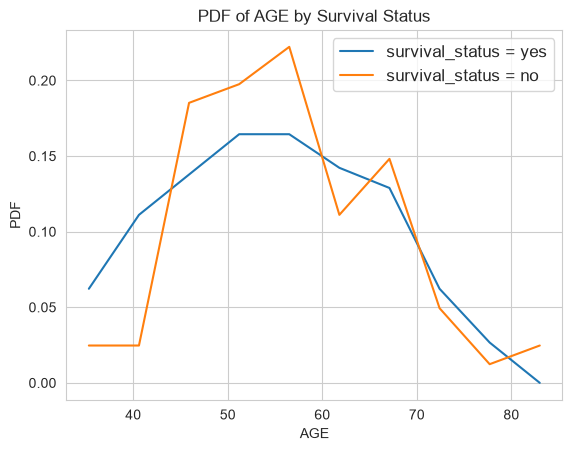

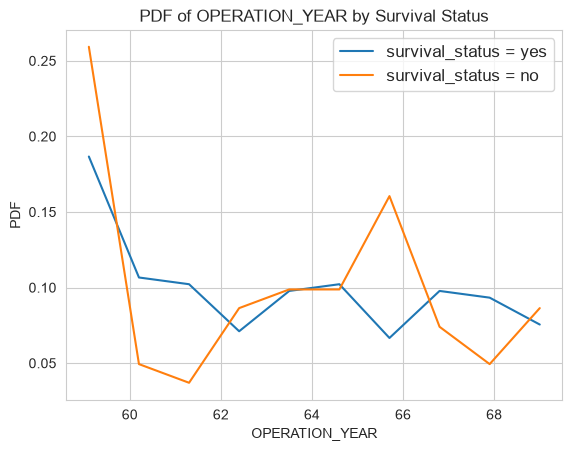

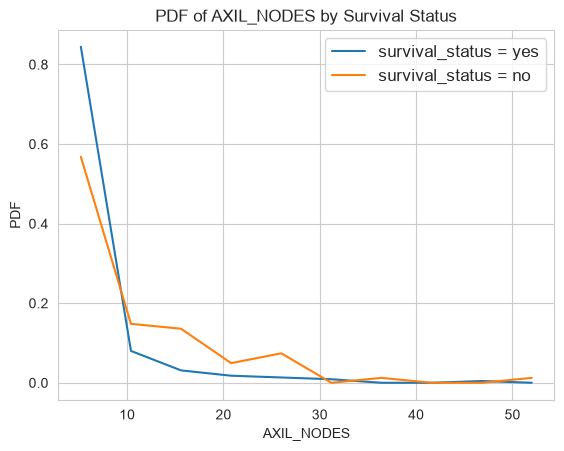

In [65]:
for feature, label in [("age", "AGE"), ("operation_year", "OPERATION_YEAR"), ("axil_nodes", "AXIL_NODES")]:
    bins = np.histogram_bin_edges(haberman[feature], bins=10)   # same bins for both classes
    for status in ["yes", "no"]:
        values = haberman.loc[haberman["survival_status"] == status, feature]
        counts, bin_edges = np.histogram(values, bins=bins, density=True)
        pdf = counts / sum(counts)
        plt.plot(bin_edges[1:], pdf, label=f"survival_status = {status}")
    plt.ylabel("PDF")
    plt.xlabel(label)
    plt.title(f"PDF of {label} by Survival Status")
    plt.legend(prop={"size": 12})
    plt.show()

* Observation

1. The probability distribution function (PDF) for the people who survived and those who died different in case of axil_nodes. Hence, axil_nodes is the most important feature to predict the survival_status after $5$ years.

2. The survival rate is extremely high for pariens having less than $3$ axil_nodes.

### _CDF (Cumulative Distribution Function)_

Cumulative distribution function (CDF) of a real-valued random variable x, or distribution function of x, evaluated at x, is the probability that the random variable will take a value less than or equal to x.

* The advantage of the cumulative distribution function is that it can be defined for any kind of random variable (discrete, continuous and mixed).
* CDFs of a random variable is defined for all real numbers.
* CDFs is defined for all real vlues x, sometimes implicitly rather than explicitly.
* This is a standard technique in statistical analysis, and this new function that we obtain by integrating the entire provavility density function is called the cumulative distribution function

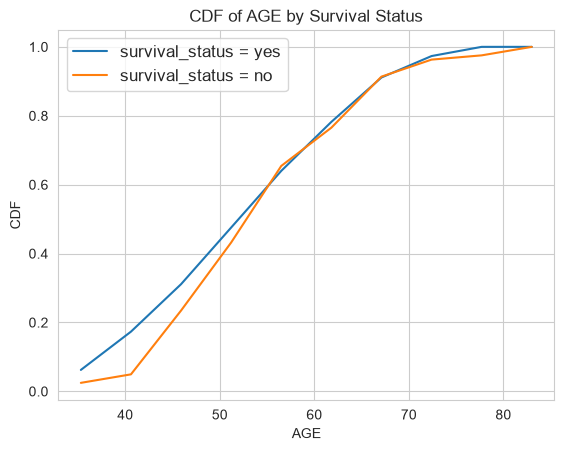

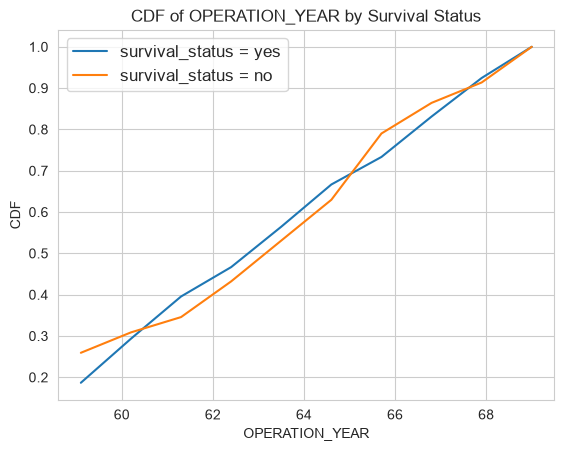

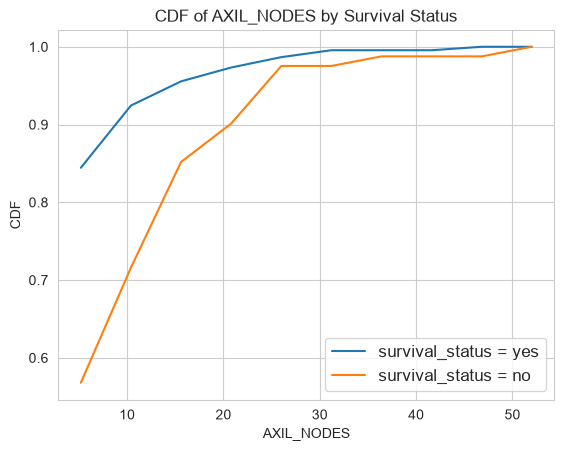

In [66]:
for feature, label in [("age", "AGE"), ("operation_year", "OPERATION_YEAR"), ("axil_nodes", "AXIL_NODES")]:
    bins = np.histogram_bin_edges(haberman[feature], bins=10)   # same bins for both classes
    for status in ["yes", "no"]:
        values = haberman.loc[haberman["survival_status"] == status, feature]
        counts, bin_edges = np.histogram(values, bins=bins, density=True)
        pdf = counts / sum(counts)
        cdf = np.cumsum(pdf)
        plt.plot(bin_edges[1:], cdf, label=f"survival_status = {status}")
    plt.ylabel("CDF")
    plt.xlabel(label)
    plt.title(f"CDF of {label} by Survival Status")
    plt.legend(prop={"size": 12})
    plt.show()

* Observation

1. From the PDF and CDF we can say that almost all survivors (about 99.6%) had fewer than 40 axil_nodes (the maximum for a survivor is 46), and about 92% of survivors had fewer than 10 axil_nodes.

### _Box Plot_

Box plot shows the distribution of quantitative data in a way that facilitates comparisons between variables or across levels of a categorical variable. The box shows the quartiles of the dataset while the whiskers extend to show the rest of the distribution, except for points that are determined to be "outliers" using a method that is a function of the inter-quartile range.

* Efficient way for presenting data, especially when it comes to comparing multiple groups thereof.
* We can mark-off the five number summary of a data set (minimum, $25th$ percentile, median,$75th$ percentile,, maximum).
* The box contains $50$% of the data, and the upper edge of the box represents the $75th$ percentile, while the lower edge is the $25th$ percentile.
* The median is represented by a line drawn in the middle of the box.
* The interquartile range (IQR) is the difference between the upper quartile and the lower quartile.
* Useful because it is less influenced by extreme values as it limits the range to the middle $50$% of the values.

**History of Box plot :-** The range-bar method was first introduced by Mary Eleanor Spear in her book `Charting Statistics` in $1952$ and again in her book `Practical Charting Techniques` in $1969$. The box-and-whisker plot was first introduced in $1970$ by John Tukey, who later published on the subject in his book `Exploratory Data Analysis` in $1977$.

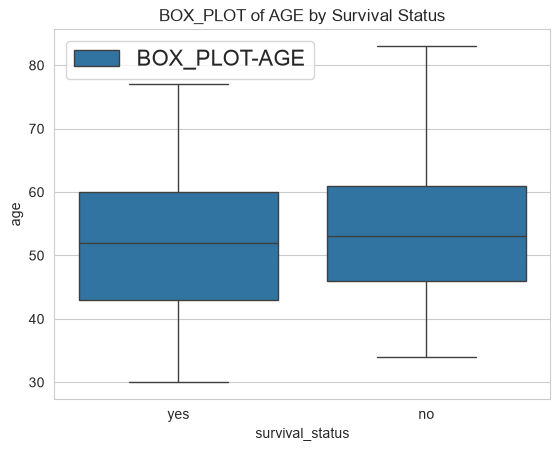

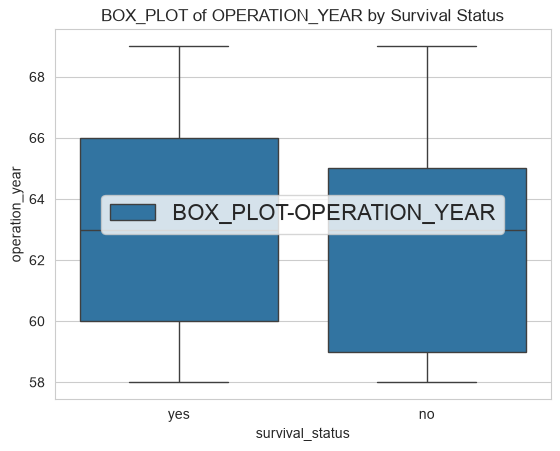

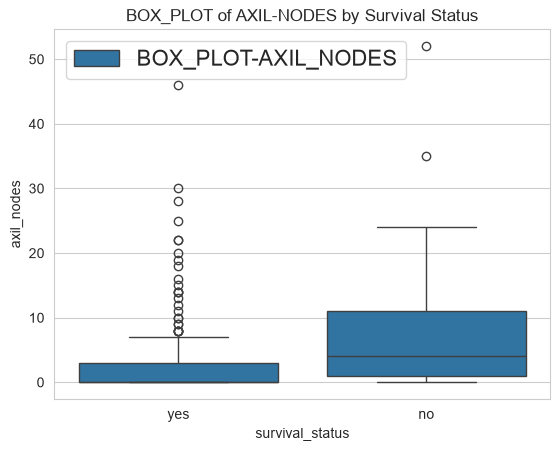

In [67]:
sbn.boxplot(x="survival_status", y="age", data=haberman)
plt.ylabel("age")
plt.xlabel("survival_status")
plt.title("BOX_PLOT of AGE by Survival Status")
plt.legend(["BOX_PLOT-AGE"], prop={"size": 16})
plt.show()

sbn.boxplot(x="survival_status", y="operation_year", data=haberman)
plt.ylabel("operation_year")
plt.xlabel("survival_status")
plt.title("BOX_PLOT of OPERATION_YEAR by Survival Status")
plt.legend(["BOX_PLOT-OPERATION_YEAR"], prop={"size": 16})
plt.show()

sbn.boxplot(x="survival_status", y="axil_nodes", data=haberman)
plt.ylabel("axil_nodes")
plt.xlabel("survival_status")
plt.title("BOX_PLOT of AXIL-NODES by Survival Status")
plt.legend(["BOX_PLOT-AXIL_NODES"], prop={"size": 16})
plt.show()

* Observation

1. Boxplot of $1$ had only $75th$ percentile value at axil_nodes is $2$ and the $25th$ and $50th$ percentiles are ovelapped.

2. Boxplot of $2$ had only $25th$ percentile value at axil_nodes is $1,50th$ percentile value at axil_nodes is $3$ and $75th$ percentile value at axil_nodes is $11$.

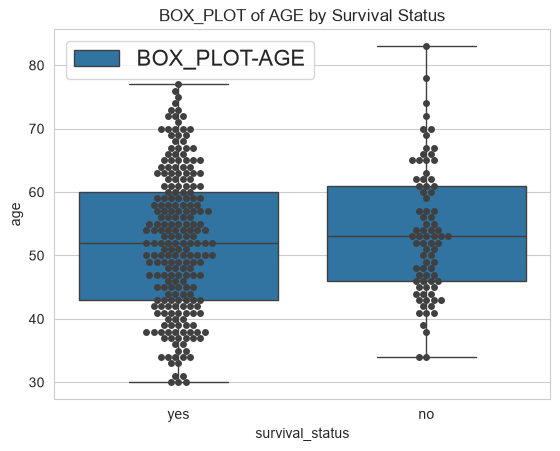

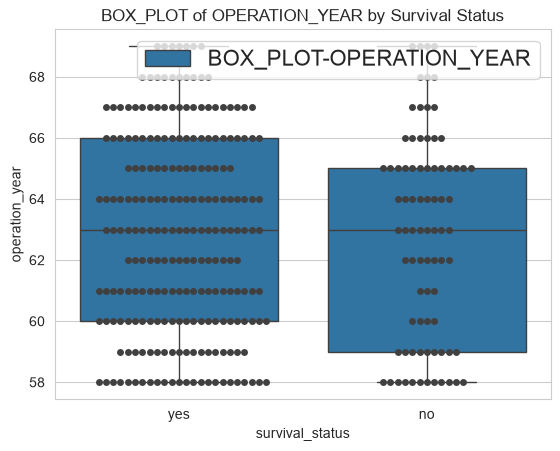

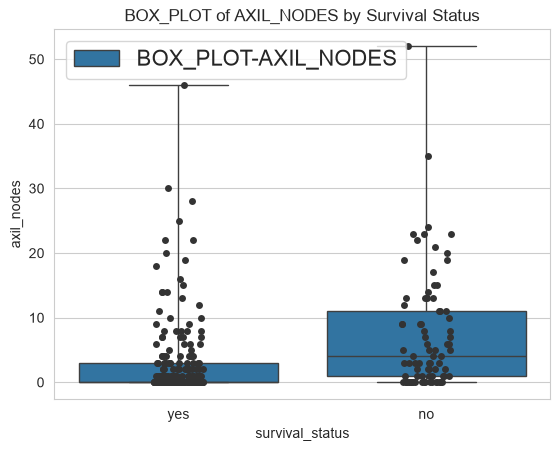

In [68]:
ax = sbn.boxplot(x="survival_status", y="age", data=haberman)
ax = sbn.swarmplot(x="survival_status", y="age", data=haberman, color=".25")
plt.ylabel("age")
plt.xlabel("survival_status")
plt.title("BOX_PLOT of AGE by Survival Status")
plt.legend(["BOX_PLOT-AGE"], prop={"size": 16})
plt.show()

ax = sbn.boxplot(x="survival_status", y="operation_year", data=haberman)
ax = sbn.swarmplot(x="survival_status", y="operation_year", data=haberman, color=".25")
plt.ylabel("operation_year")
plt.xlabel("survival_status")
plt.title("BOX_PLOT of OPERATION_YEAR by Survival Status")
plt.legend(["BOX_PLOT-OPERATION_YEAR"], prop={"size": 16})
plt.show()

ax = sbn.boxplot(x="survival_status", y="axil_nodes", data=haberman, whis=np.inf)
ax = sbn.stripplot(x="survival_status", y="axil_nodes", data=haberman, color=".2")
plt.ylabel("axil_nodes")
plt.xlabel("survival_status")
plt.title("BOX_PLOT of AXIL_NODES by Survival Status")
plt.legend(["BOX_PLOT-AXIL_NODES"], prop={"size": 16})
plt.show()

### _Violin Plot_

A violin plot is a statistical graphic for comparing probability distributions. It is similar to a box plot, with the addition of a rotated kernel density plot on each side.

* Violin plot is a method of plotting numeric data.
* It's a combination of a Box plot and a Density plot.
* The thick black bar in the center represents the interquartile range, the thin black line extended from it represents the $95$% confidence intervals, and the white dot is the median.

**History of Violin Plot :-** The violin plot was proposed in $1997$ by Jerry L. Hintze and Ray D. Nelson as a way to display even more information than box plots, which were created by John Tukey in $1977$. The name comes from the plot's alleged resemblance to a violin.

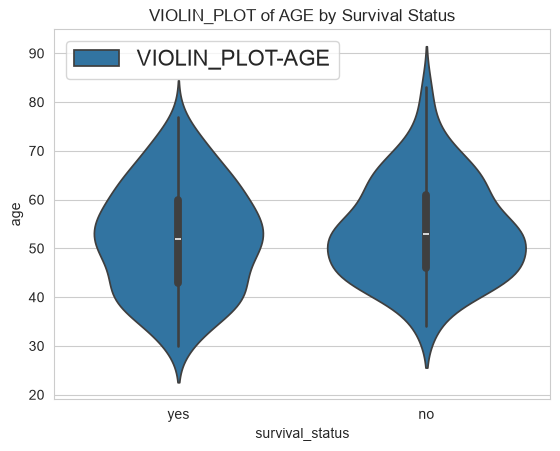

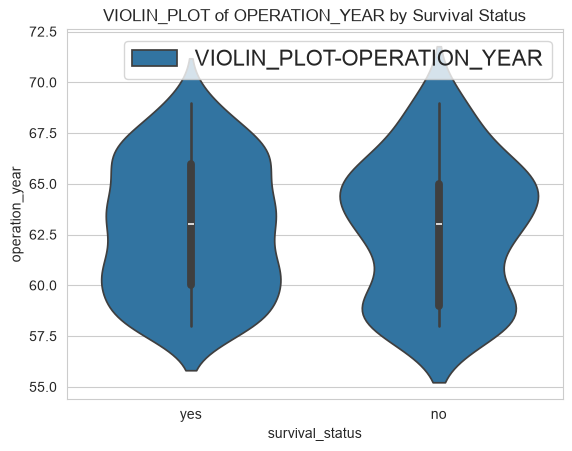

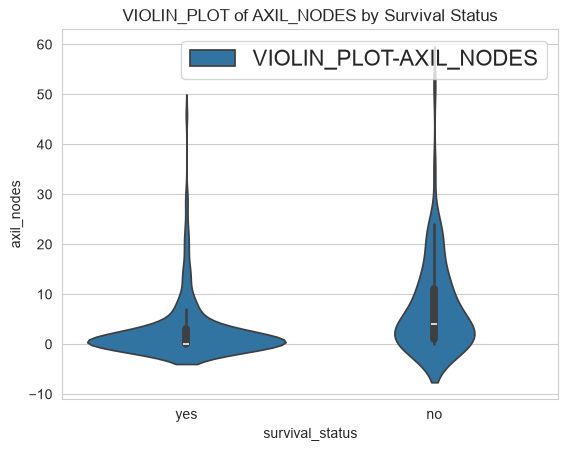

In [69]:
sbn.violinplot(x="survival_status", y="age", data=haberman)
plt.ylabel("age")
plt.xlabel("survival_status")
plt.title("VIOLIN_PLOT of AGE by Survival Status")
plt.legend(["VIOLIN_PLOT-AGE"], prop={"size": 16})
plt.show()

sbn.violinplot(x="survival_status", y="operation_year", data=haberman)
plt.ylabel("operation_year")
plt.xlabel("survival_status")
plt.title("VIOLIN_PLOT of OPERATION_YEAR by Survival Status")
plt.legend(["VIOLIN_PLOT-OPERATION_YEAR"], prop={"size": 16})
plt.show()

sbn.violinplot(x="survival_status", y="axil_nodes", data=haberman)
plt.ylabel("axil_nodes")
plt.xlabel("survival_status")
plt.title("VIOLIN_PLOT of AXIL_NODES by Survival Status")
plt.legend(["VIOLIN_PLOT-AXIL_NODES"], prop={"size": 16})
plt.show()

* Observation

1. $50th$ percent of survivors have $0$ positive nodes, $75th$ percent of survivors have less than $3$ positive axillary nodes.

2. $25th$ percent of dead have $1$ positive axillary node, $50th$ percent of dead have positive axillary nodes below $4$.

3. $75th$ percent of dead have positive nodes below $11$.

4. The number of survival_status of the survivors is highly densed from $0$ to $5$.

5. About $84$% of the survivors have $5$ or fewer positive axillary nodes (about $77$% of all patients).

6. From box plots and violin plots, we can say that more no of patients who are dead have age between $46-62$ or $59-65$ and the patients who survived have age between $42-60$ or $60-66$.

## _Bivariate analysis_

Bivariate analysis is one of the simplest forms of quantitative (statistical) analysis. It involves the analysis of two variables (often denoted as X, Y), for the purpose of determining the empirical relationship between them. It means the analysis of bivariate data. It is one of the simplest forms of statistical analysis, used to find out if ther is a relationship betweeen two sets of balues. It usually involves the variables X and Y.

### _Scatter Plot_

Scatter plot is a type of plot or mathematical diagram using Cartesian coordinates to display values for typically two variables for a set of data. If the points are coded (color/shape/size), one additional variable can be displayed. The data are displayed as a collection of points, each having the value of one variable determining the position on the horizontal axis and the value of the other variable determining the position on the vertical axis

* Visualizes the bivariate relationships among several pairs of variavles.

* The graph looks like a bunch of dots, but some of the graphs are a general shape or move in a general direction.

* To test the linear relationship between continuous variables scatter plot is a good option. We can find out how one variable is changing w.r.t another variable.

#### _1D Scatter plot_

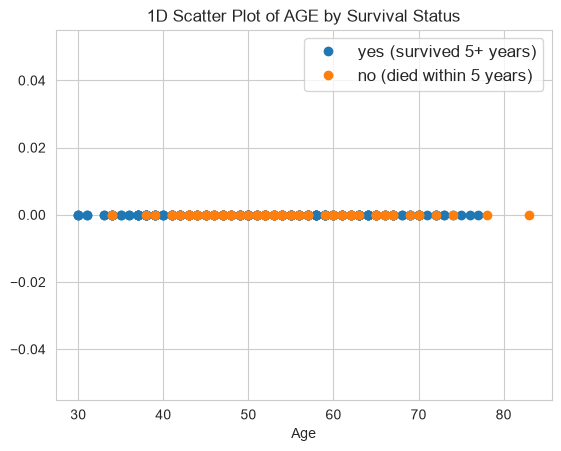

In [70]:
X = haberman.loc[haberman["survival_status"] == "yes"]
Y = haberman.loc[haberman["survival_status"] == "no"]
plt.plot(X["age"], np.zeros_like(X["age"]), "o", label="yes (survived 5+ years)")
plt.plot(Y["age"], np.zeros_like(Y["age"]), "o", label="no (died within 5 years)")
plt.xlabel("Age")
plt.title("1D Scatter Plot of AGE by Survival Status")
plt.legend(prop={"size": 12})
plt.show()

#### _2D Scatter plot_

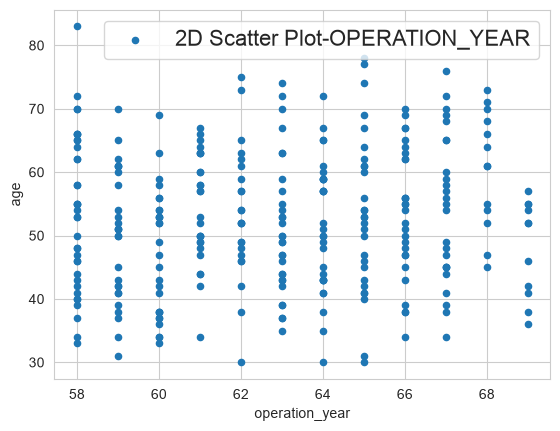

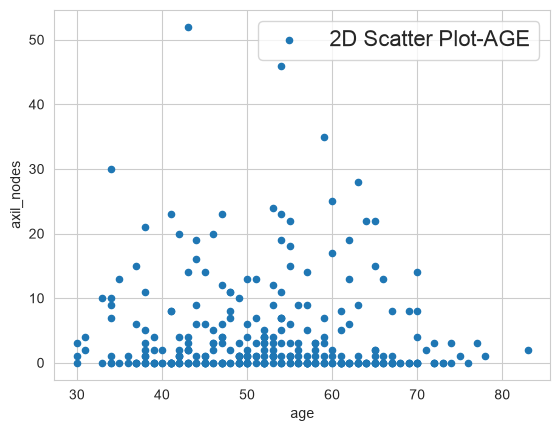

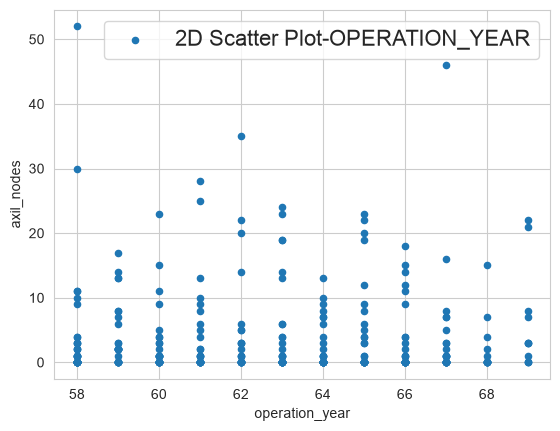

In [71]:
haberman.plot(kind="scatter", x="operation_year", y="age")
plt.ylabel("age")
plt.xlabel("operation_year")
plt.legend(["2D Scatter Plot-OPERATION_YEAR"], prop={"size": 16})
plt.show()

haberman.plot(kind="scatter", x="age", y="axil_nodes")
plt.ylabel("axil_nodes")
plt.xlabel("age")
plt.legend(["2D Scatter Plot-AGE"], prop={"size": 16})
plt.show()

haberman.plot(kind="scatter", x="operation_year", y="axil_nodes")
plt.ylabel("axil_nodes")
plt.xlabel("operation_year")
plt.legend(["2D Scatter Plot-OPERATION_YEAR"], prop={"size": 16})
plt.show()

#### _Scatter plot coloured by class (FacetGrid)_

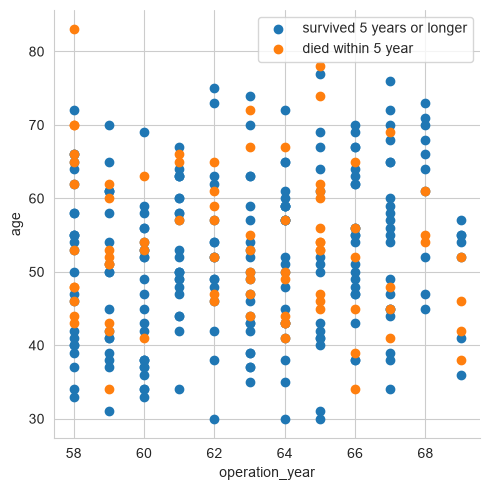

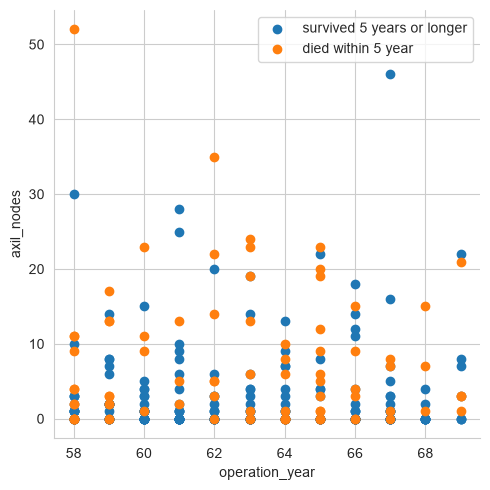

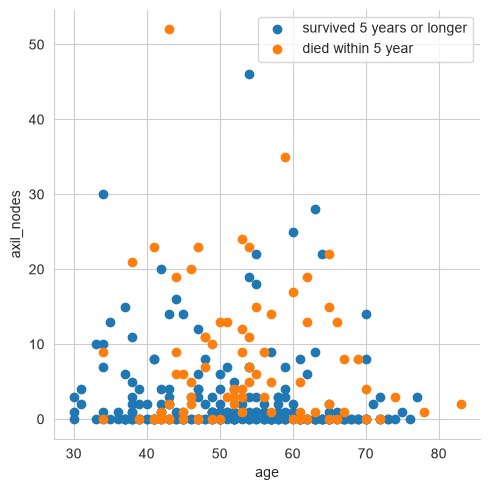

In [72]:
label = ['survived 5 years or longer','died within 5 year']
sbn.set_style("whitegrid");
sbn.FacetGrid(haberman, hue="survival_status", height=5).map(plt.scatter,"operation_year", "age")  
plt.ylabel("age")
plt.xlabel('operation_year')
plt.legend(label)
plt.show() 

label = ['survived 5 years or longer','died within 5 year']
sbn.set_style("whitegrid");
sbn.FacetGrid(haberman, hue="survival_status", height=5).map(plt.scatter,"operation_year", "axil_nodes")  
plt.ylabel("axil_nodes")
plt.xlabel('operation_year')
plt.legend(label)
plt.show() 

label = ['survived 5 years or longer','died within 5 year']
sbn.set_style("whitegrid");
sbn.FacetGrid(haberman, hue="survival_status", height=5).map(plt.scatter,"age", "axil_nodes")
plt.ylabel("axil_nodes")
plt.xlabel('age')
plt.legend(label)
plt.show()

* Observation

1. It seems most of the patients have 0 positive lymph nodes detected.
2. Here we clearly see that blue points are not seperated from orange points
3. So, by looking at this 2D scatter plot between 'Age' and 'positive_lymph_nodes' we can't make any decision regarding patient's survival.
4. Therefore, we have to check all combination/pair of features to make good classification/decision.
5. Number of Combinations of features : 3C2 = 3 (excluding class-attribute 'Survival')
6. Now, for these combination to analyse, Pair-Plot concept is used.

### _Scatter plot with class colours_

The earlier 2D scatter plots had no class information. Here the colour **and** the marker shape show `survival_status`, so every pair of features can be judged for class separation.

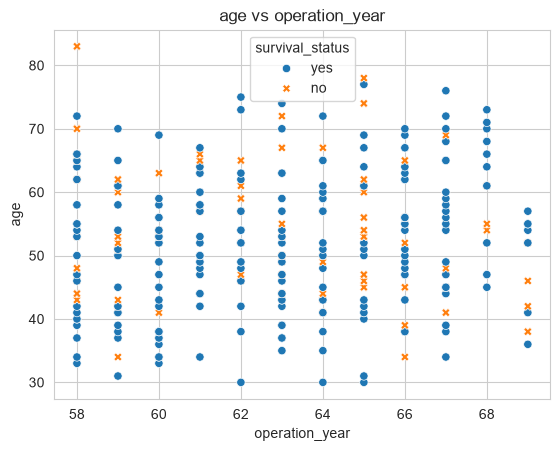

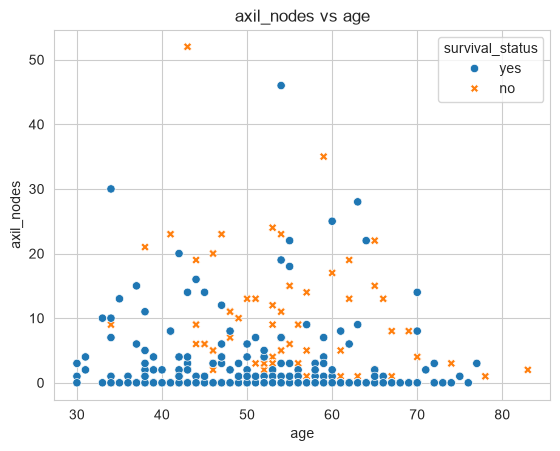

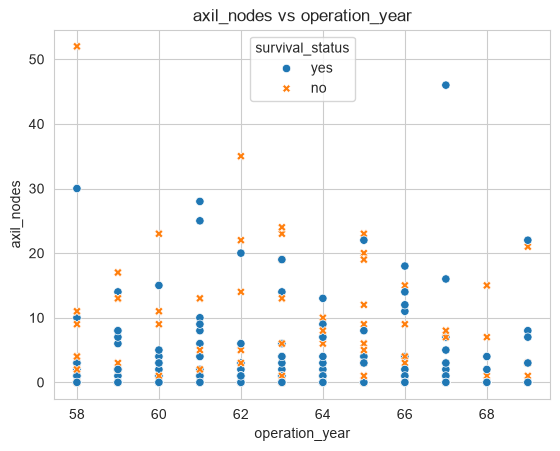

In [73]:
sbn.scatterplot(data=haberman, x="operation_year", y="age", hue="survival_status", style="survival_status")
plt.title("age vs operation_year")
plt.show()

sbn.scatterplot(data=haberman, x="age", y="axil_nodes", hue="survival_status", style="survival_status")
plt.title("axil_nodes vs age")
plt.show()

sbn.scatterplot(data=haberman, x="operation_year", y="axil_nodes", hue="survival_status", style="survival_status")
plt.title("axil_nodes vs operation_year")
plt.show()

* Observation

1. In all three plots the two classes are mixed together, so no pair of features separates `yes` from `no` cleanly.
2. `operation_year` takes whole-number values only, so its points sit in vertical stripes and many overlap.
3. In the two plots that use `axil_nodes`, the orange `no` points are more common higher up the y-axis, while the blue `yes` points cluster at 0 nodes.

#### _Interactive 3D scatter plot_

All three features at once. The plot can be rotated and zoomed, and clicking a legend entry hides that class.

In [74]:
fig = px.scatter_3d(haberman, x="age", y="operation_year", z="axil_nodes",
                    color="survival_status", title="3D Scatter Plot", opacity=0.8)
fig.update_traces(marker_size=4)
fig.show()

* Observation

1. Even with all three features, the classes are intermixed; no clean separating surface is visible.
2. The only visible trend is along the `axil_nodes` axis, where the high points are mostly `no`.

### _Pair Plot_

A pair plot draws every pair of features in one grid. The diagonal shows each feature's own distribution per class, and the plots above and below the diagonal are the same pairs with the axes swapped.

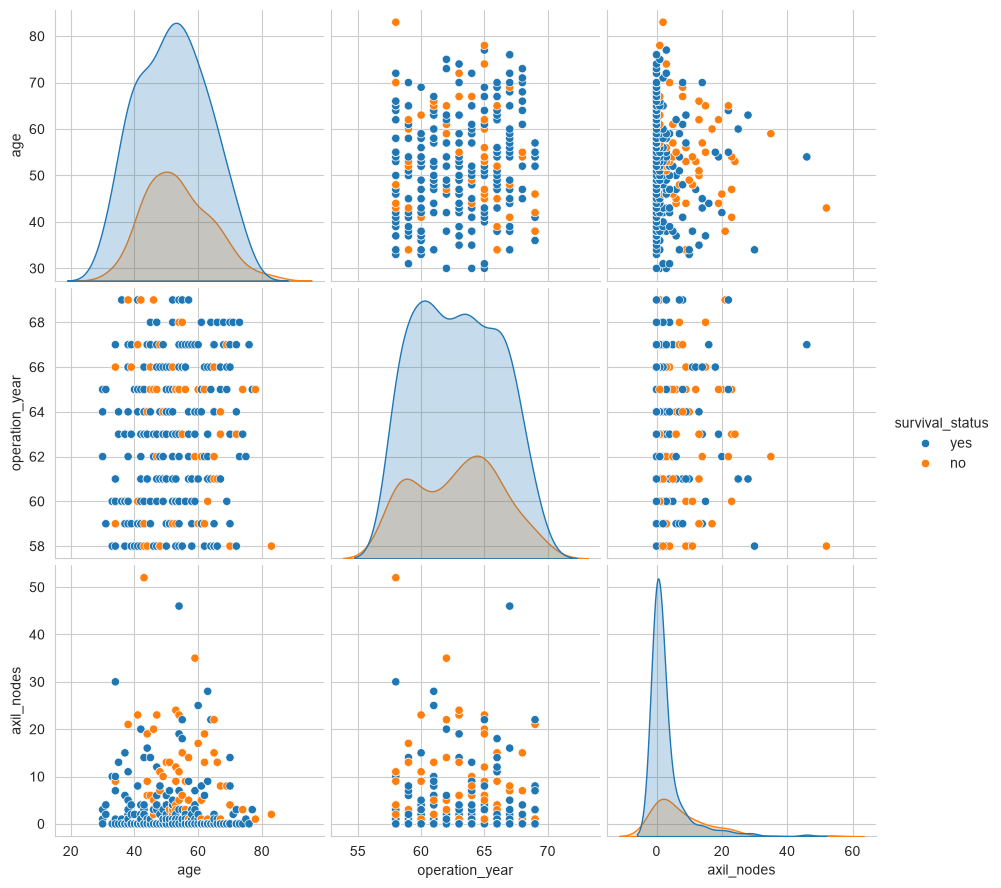

In [75]:
sbn.set_style("whitegrid")
sbn.pairplot(haberman, hue="survival_status", vars=["age", "operation_year", "axil_nodes"], height=3)
plt.show()

Same pair plot with **histograms** on the diagonal instead of density curves:

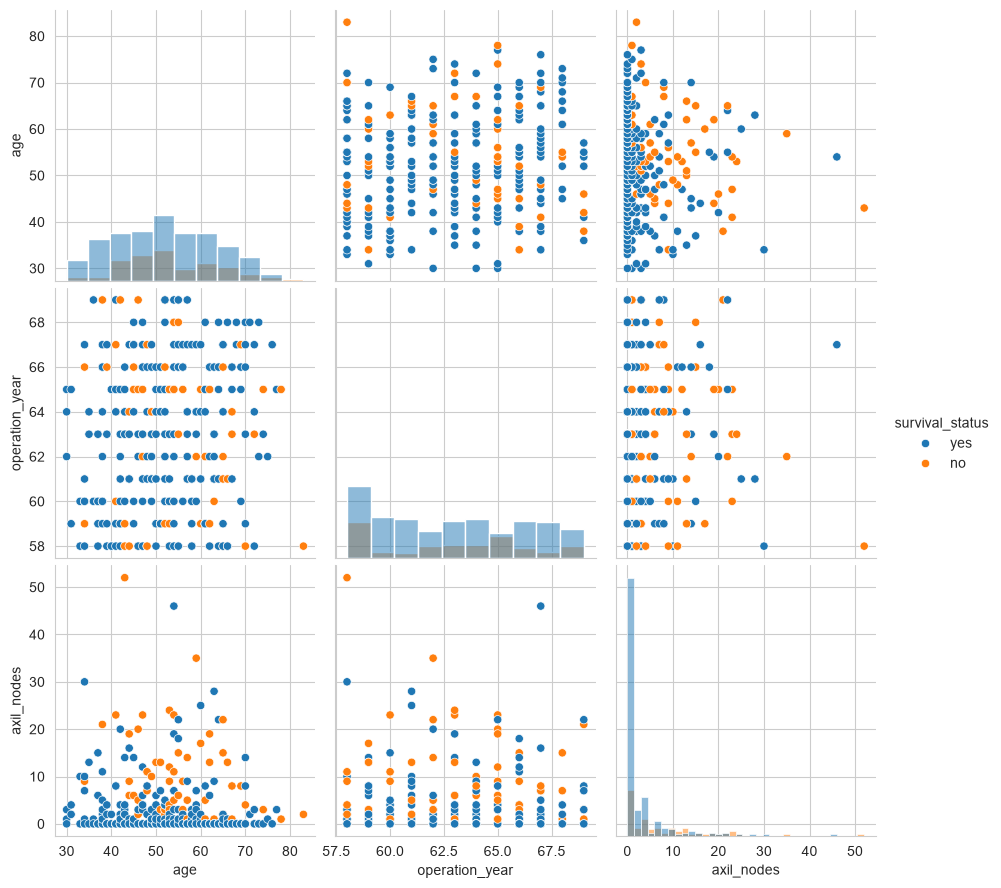

In [76]:
sbn.pairplot(haberman, hue="survival_status", vars=["age", "operation_year", "axil_nodes"],
             diag_kind="hist", height=3)
plt.show()

With `corner=True` only the lower triangle is drawn, because the upper triangle repeats it, and with different marker shapes per class:

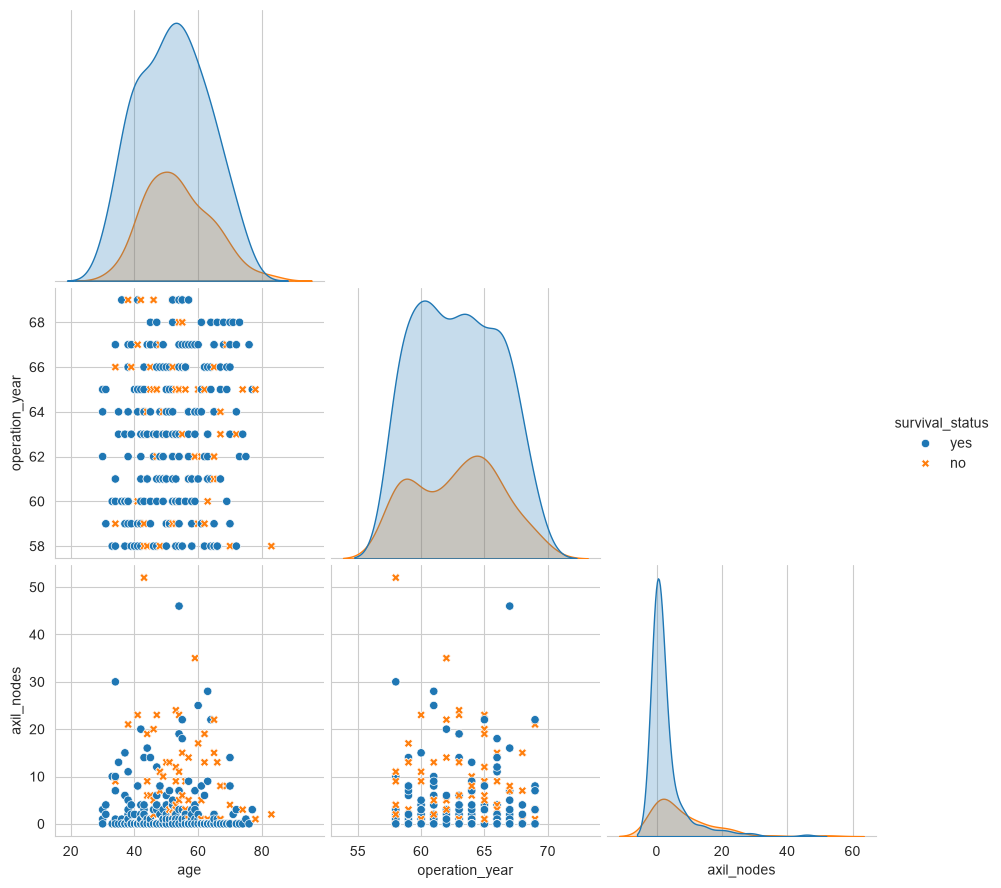

In [77]:
sbn.pairplot(haberman, hue="survival_status", vars=["age", "operation_year", "axil_nodes"],
             corner=True, markers=["o", "X"], height=3)
plt.show()

### _Contour plot_

Density contours show where the patients are concentrated.

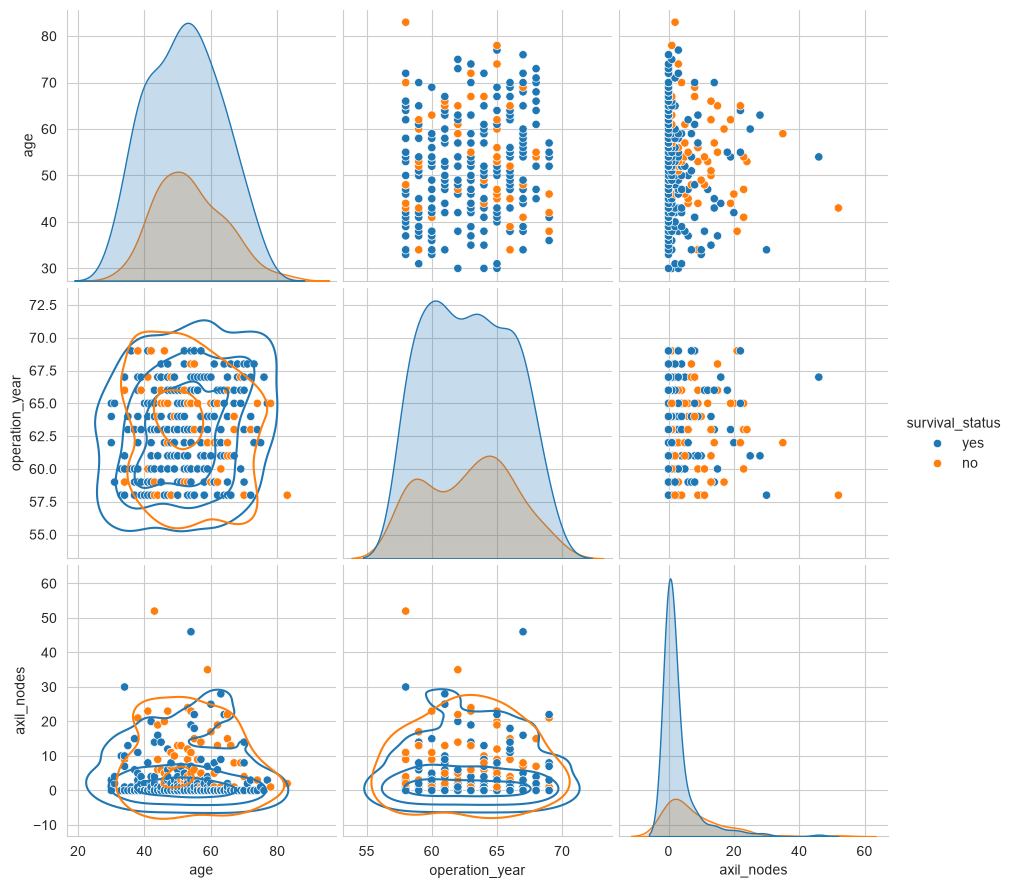

In [78]:
g = sbn.pairplot(haberman, hue="survival_status", vars=["age", "operation_year", "axil_nodes"],
                 diag_kind="kde", height=3)
g.map_lower(sbn.kdeplot, levels=4, color=".2")
plt.show()

* Observation

1. In the pair plots, the plots above the diagonal are the same as those below it with the axes swapped, so only one triangle needs to be read.
2. On the diagonal only `axil_nodes` has two clearly different shapes: survivors peak at 0, while non-survivors are spread out. `age` and `operation_year` overlap almost completely.
3. `axil_nodes` vs `age` is the most useful pair: most survivors sit at 0 nodes at every age.
4. The contour lines show that most patients were operated on between about 1958 and 1966, with fewer operations in 1968–1969.

## _All Observations_

**Number of points**
* The dataset is **unbalanced** (about 73% `yes`, 27% `no`) but complete, with no missing values.
* `survival_status` was an integer, so it was converted to the categories `yes` (survived 5 years or longer) and `no` (died within 5 years).

**PDF / CDF**
* The distributions of `age` and `operation_year` are similar for both classes. `axil_nodes` is the only feature whose distribution clearly differs.
* The survival rate is high for patients with few positive nodes.

**Box plot and violin plot**
* Survivors: median `axil_nodes` is 0 and the 75th percentile is 3.
* Non-survivors: the 25th percentile is 1, the median is 4 and the 75th percentile is 11.
* The `age` and `operation_year` boxes overlap almost completely.

**Scatter plot**
* Most patients have 0 positive nodes.
* The classes overlap in every pair of features.

**Pair plot**
* Only `axil_nodes` shows different shapes for the two classes on the diagonal; the off-diagonal plots all overlap.

## _Conclusions_

1. The data is **imbalanced**: about 73% of patients survived 5 years or longer and about 27% died within 5 years. Plain accuracy would be misleading for any model built on it.
2. **`axil_nodes` is the only useful single feature.** Survivors have a mean of about 2.8 positive nodes and non-survivors about 7.5. The median is 0 for survivors and 4 for non-survivors, and about 52% of survivors have 0 nodes against about 23.5% of non-survivors.
3. The survival rate falls as the number of nodes rises: about 86% with 0 nodes, 75% with 1–3, 61% with 4–10 and 42% with more than 10.
4. **`age` and `operation_year` are poor features.** Their distributions are almost the same for both classes (mean age about 52.0 for survivors and 53.7 for non-survivors).
5. In the scatter plots and the pair plots the two classes **overlap heavily**, so no pair of features separates them cleanly.
6. A high node count is not a rule: one patient with 46 positive nodes survived and one with 52 did not, so there is no single cut-off value.
7. The features are almost uncorrelated with each other (the largest correlation is about 0.09), so they carry independent information.
8. Overall, these three features give only moderate predictive power. Models such as logistic regression or a decision tree could be tried next, judged with precision, recall and ROC-AUC.